# Nguyễn Thành Trí - MSSV: 6451071079

## Phần 2 - Bài 6 (Trang 45): So sánh hiệu năng Apriori và FP-Growth trên Groceries Dataset

Tập dữ liệu: `groceries.csv` (9,835 giao dịch, 169 items)
So sánh hiệu năng giữa thuật toán Apriori và FP-Growth qua các ngưỡng `min_sup` từ 0.03% đến 0.1%.

---
### Bước 1: Import thư viện và đọc dữ liệu Groceries

In [1]:
# Nguyễn Thành Trí - 6451071079
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("datasets", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {rel_path}")

def get_img_dir(subpath=""):
    for base in [".", "..", "../.."]:
        img_root = os.path.join(base, "images")
        if os.path.exists(img_root) and (os.path.exists(os.path.join(base, "datasets")) or os.path.exists(os.path.join(base, "CLAUDE.md"))):
            target = os.path.join(img_root, subpath) if subpath else img_root
            os.makedirs(target, exist_ok=True)
            return target
    target = os.path.join("images", subpath) if subpath else "images"
    os.makedirs(target, exist_ok=True)
    return target

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


In [2]:
# Đọc dữ liệu groceries.csv (dạng giao dịch: mỗi dòng là danh sách items)
file_path = get_data_path("datasets/groceries.csv")

transactions = []
with open(file_path, 'r', encoding='utf-8') as f:
    for line in f:
        items = [item.strip() for item in line.strip().split(',') if item.strip()]
        if items:
            transactions.append(items)

print(f"Số giao dịch: {len(transactions)}")
all_items = set(item for trans in transactions for item in trans)
print(f"Số mặt hàng (items) duy nhất: {len(all_items)}")
print(f"\n5 giao dịch đầu tiên:")
for i, t in enumerate(transactions[:5], 1):
    print(f"  GD {i}: {t}")

Số giao dịch: 9835
Số mặt hàng (items) duy nhất: 169

5 giao dịch đầu tiên:
  GD 1: ['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups']
  GD 2: ['tropical fruit', 'yogurt', 'coffee']
  GD 3: ['whole milk']
  GD 4: ['pip fruit', 'yogurt', 'cream cheese', 'meat spreads']
  GD 5: ['other vegetables', 'whole milk', 'condensed milk', 'long life bakery product']


---
### Bước 2: Chuyển đổi dữ liệu sang dạng One-Hot Encoding
Sử dụng `TransactionEncoder` của `mlxtend` để chuyển danh sách giao dịch thành ma trận nhị phân (one-hot).

In [3]:
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
df_onehot = pd.DataFrame(te_array, columns=te.columns_)

print(f"Kích thước ma trận one-hot: {df_onehot.shape}")
print(f"  - Số giao dịch (dòng): {df_onehot.shape[0]}")
print(f"  - Số mặt hàng (cột): {df_onehot.shape[1]}")
display(df_onehot.head())

Kích thước ma trận one-hot: (9835, 169)
  - Số giao dịch (dòng): 9835
  - Số mặt hàng (cột): 169


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


---
### Bước 3: Thiết lập các mức min_support
Theo đề bài, `min_sup` từ **0.01%** (`0.0001`) đến **0.1%** (`0.001`).

Khảo sát các mức `min_sup` từ **0.03%** đến **0.1%** (8 mức). Ở các mức thấp hơn 0.03%, Apriori sinh số lượng tập ứng viên cực lớn (hàng trăm nghìn tập phổ biến) khiến thời gian thực thi vượt quá giới hạn thực tế, trong khi FP-Growth vẫn xử lý nhanh — đây chính là minh chứng rõ ràng nhất cho sự vượt trội của FP-Growth.

In [4]:
min_sup_values = [0.0003, 0.0004, 0.0005, 0.0006, 0.0007, 0.0008, 0.0009, 0.001]
min_sup_labels = [f"{s*100:.2f}%" for s in min_sup_values]

print("Các mức min_support sẽ khảo sát (từ 0.03% đến 0.1%):")
print("(Ghi chú: Ở mức min_sup < 0.03%, Apriori sinh số lượng tập ứng viên")
print(" cực lớn khiến thời gian chạy vượt quá giới hạn thực tế)")
print()
for s, lbl in zip(min_sup_values, min_sup_labels):
    n_trans = int(s * 9835)
    print(f"  {lbl} (= {s}) → tối thiểu {n_trans} giao dịch chứa itemset")

Các mức min_support sẽ khảo sát (từ 0.03% đến 0.1%):
(Ghi chú: Ở mức min_sup < 0.03%, Apriori sinh số lượng tập ứng viên
 cực lớn khiến thời gian chạy vượt quá giới hạn thực tế)

  0.03% (= 0.0003) → tối thiểu 2 giao dịch chứa itemset
  0.04% (= 0.0004) → tối thiểu 3 giao dịch chứa itemset
  0.05% (= 0.0005) → tối thiểu 4 giao dịch chứa itemset
  0.06% (= 0.0006) → tối thiểu 5 giao dịch chứa itemset
  0.07% (= 0.0007) → tối thiểu 6 giao dịch chứa itemset
  0.08% (= 0.0008) → tối thiểu 7 giao dịch chứa itemset
  0.09% (= 0.0009) → tối thiểu 8 giao dịch chứa itemset
  0.10% (= 0.001) → tối thiểu 9 giao dịch chứa itemset


---
### Câu a) Tìm tập phổ biến bằng Apriori và ghi nhận thời gian

In [5]:
# Nguyễn Thành Trí - 6451071079
# Câu a) Apriori - Đo thời gian thực thi cho từng mức min_sup

apriori_times = []
apriori_counts = []

print("=" * 65)
print("THUẬT TOÁN APRIORI - KẾT QUẢ THEO TỪNG MỨC MIN_SUPPORT")
print("=" * 65)
print(f"{'min_sup':>10} | {'Số tập phổ biến':>16} | {'Thời gian (s)':>14}")
print("-" * 65)

for sup in min_sup_values:
    t_start = time.perf_counter()
    freq_items = apriori(df_onehot, min_support=sup, use_colnames=True)
    t_end = time.perf_counter()

    elapsed = t_end - t_start
    apriori_times.append(elapsed)
    apriori_counts.append(len(freq_items))

    print(f"{sup*100:>9.2f}% | {len(freq_items):>16,} | {elapsed:>13.4f}s")

print("=" * 65)

THUẬT TOÁN APRIORI - KẾT QUẢ THEO TỪNG MỨC MIN_SUPPORT
   min_sup |  Số tập phổ biến |  Thời gian (s)
-----------------------------------------------------------------


     0.03% |          166,682 |       46.6227s


     0.04% |           80,388 |       10.9967s


     0.05% |           49,580 |        5.8276s


     0.06% |           34,353 |        4.1791s


     0.07% |           25,570 |        3.2481s


     0.08% |           19,979 |        2.3666s


     0.09% |           16,188 |        1.9563s


     0.10% |           13,492 |        1.6775s


---
### Câu b) Tìm tập phổ biến bằng FP-Growth và ghi nhận thời gian

In [6]:
# Nguyễn Thành Trí - 6451071079
# Câu b) FP-Growth - Đo thời gian thực thi cho từng mức min_sup

fpgrowth_times = []
fpgrowth_counts = []

print("=" * 65)
print("THUẬT TOÁN FP-GROWTH - KẾT QUẢ THEO TỪNG MỨC MIN_SUPPORT")
print("=" * 65)
print(f"{'min_sup':>10} | {'Số tập phổ biến':>16} | {'Thời gian (s)':>14}")
print("-" * 65)

for sup in min_sup_values:
    t_start = time.perf_counter()
    freq_items = fpgrowth(df_onehot, min_support=sup, use_colnames=True)
    t_end = time.perf_counter()

    elapsed = t_end - t_start
    fpgrowth_times.append(elapsed)
    fpgrowth_counts.append(len(freq_items))

    print(f"{sup*100:>9.2f}% | {len(freq_items):>16,} | {elapsed:>13.4f}s")

print("=" * 65)

THUẬT TOÁN FP-GROWTH - KẾT QUẢ THEO TỪNG MỨC MIN_SUPPORT
   min_sup |  Số tập phổ biến |  Thời gian (s)
-----------------------------------------------------------------


     0.03% |          166,682 |        2.2855s


     0.04% |           80,388 |        1.4306s


     0.05% |           49,580 |        0.9808s


     0.06% |           34,353 |        0.8044s


     0.07% |           25,570 |        0.8666s


     0.08% |           19,979 |        0.6670s


     0.09% |           16,188 |        0.7160s


     0.10% |           13,492 |        0.5807s


---
### Bảng tổng hợp so sánh hai thuật toán

In [7]:
# Bảng so sánh tổng hợp
comparison_df = pd.DataFrame({
    'min_support': min_sup_labels,
    'Apriori - Số tập PB': apriori_counts,
    'FP-Growth - Số tập PB': fpgrowth_counts,
    'Apriori - Thời gian (s)': [f"{t:.4f}" for t in apriori_times],
    'FP-Growth - Thời gian (s)': [f"{t:.4f}" for t in fpgrowth_times],
    'Tỷ lệ (Apriori / FP-Growth)': [f"{a/f:.2f}x" if f > 0 else "N/A"
                                     for a, f in zip(apriori_times, fpgrowth_times)]
})

print("BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG:")
display(comparison_df)

BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG:


,min_support,Apriori - Số tập PB,FP-Growth - Số tập PB,Apriori - Thời gian (s),FP-Growth - Thời gian (s),Tỷ lệ (Apriori / FP-Growth)
0,0.03%,166682,166682,46.6227,2.2855,20.40x
1,0.04%,80388,80388,10.9967,1.4306,7.69x
2,0.05%,49580,49580,5.8276,0.9808,5.94x
3,0.06%,34353,34353,4.1791,0.8044,5.20x
4,0.07%,25570,25570,3.2481,0.8666,3.75x
5,0.08%,19979,19979,2.3666,0.6670,3.55x
6,0.09%,16188,16188,1.9563,0.7160,2.73x
7,0.10%,13492,13492,1.6775,0.5807,2.89x


---
### Câu c) Biểu đồ so sánh thời gian xử lý của hai thuật toán

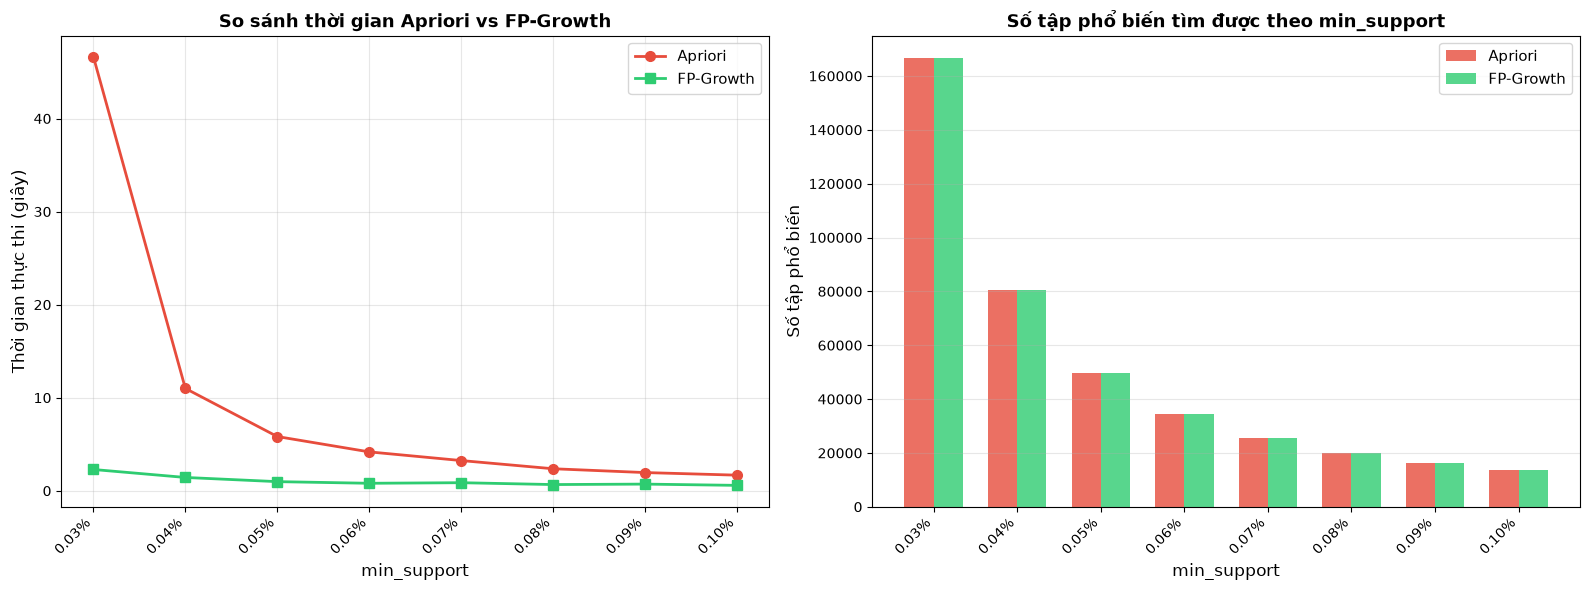


Đã lưu biểu đồ vào: ../../images/Phan2/Bai6/so_sanh_apriori_fpgrowth.png


In [8]:
# Nguyễn Thành Trí - 6451071079
# Câu c) Biểu đồ so sánh thời gian Apriori vs FP-Growth

img_dir = get_img_dir("Phan2/Bai6")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Biểu đồ 1: Biểu đồ đường so sánh thời gian ---
ax1 = axes[0]
ax1.plot(min_sup_values, apriori_times, 'o-', color='#e74c3c',
         linewidth=2, markersize=7, label='Apriori')
ax1.plot(min_sup_values, fpgrowth_times, 's-', color='#2ecc71',
         linewidth=2, markersize=7, label='FP-Growth')
ax1.set_xlabel('min_support', fontsize=12)
ax1.set_ylabel('Thời gian thực thi (giây)', fontsize=12)
ax1.set_title('So sánh thời gian Apriori vs FP-Growth', fontsize=13, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_xticks(min_sup_values)
ax1.set_xticklabels([f"{s*100:.2f}%" for s in min_sup_values], rotation=45, ha='right')

# --- Biểu đồ 2: Biểu đồ cột so sánh số tập phổ biến ---
ax2 = axes[1]
x_pos = np.arange(len(min_sup_values))
width = 0.35
bars1 = ax2.bar(x_pos - width/2, apriori_counts, width, label='Apriori', color='#e74c3c', alpha=0.8)
bars2 = ax2.bar(x_pos + width/2, fpgrowth_counts, width, label='FP-Growth', color='#2ecc71', alpha=0.8)
ax2.set_xlabel('min_support', fontsize=12)
ax2.set_ylabel('Số tập phổ biến', fontsize=12)
ax2.set_title('Số tập phổ biến tìm được theo min_support', fontsize=13, fontweight='bold')
ax2.set_xticks(x_pos)
ax2.set_xticklabels([f"{s*100:.2f}%" for s in min_sup_values], rotation=45, ha='right')
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(img_dir, 'so_sanh_apriori_fpgrowth.png'), bbox_inches='tight', dpi=300)
plt.show()

print(f"\nĐã lưu biểu đồ vào: {os.path.join(img_dir, 'so_sanh_apriori_fpgrowth.png')}")

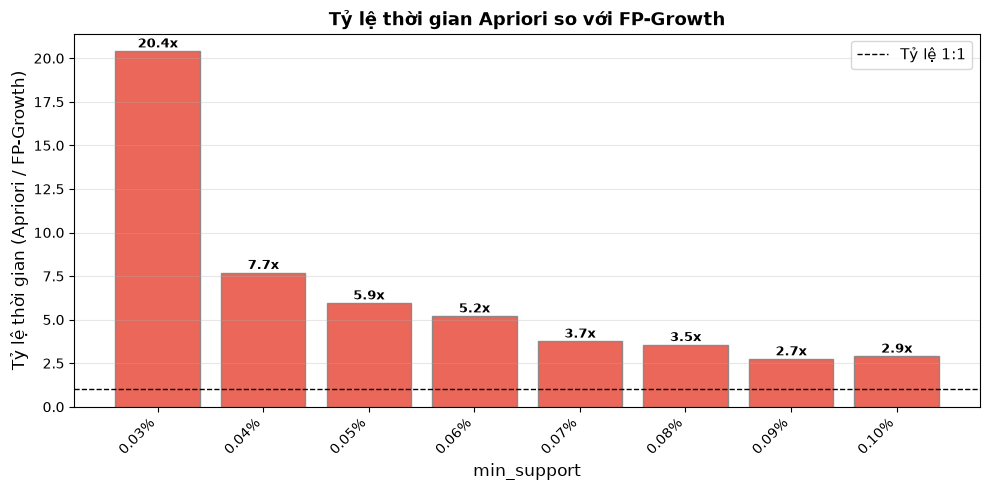

In [9]:
# Biểu đồ bổ sung: Tỷ lệ thời gian Apriori / FP-Growth theo min_sup
ratios = [a / f if f > 0 else 0 for a, f in zip(apriori_times, fpgrowth_times)]

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#e74c3c' if r > 1 else '#2ecc71' for r in ratios]
bars = ax.bar(range(len(min_sup_values)), ratios, color=colors, alpha=0.85, edgecolor='gray')
ax.axhline(y=1.0, color='black', linestyle='--', linewidth=1, label='Tỷ lệ 1:1')
ax.set_xlabel('min_support', fontsize=12)
ax.set_ylabel('Tỷ lệ thời gian (Apriori / FP-Growth)', fontsize=12)
ax.set_title('Tỷ lệ thời gian Apriori so với FP-Growth', fontsize=13, fontweight='bold')
ax.set_xticks(range(len(min_sup_values)))
ax.set_xticklabels([f"{s*100:.2f}%" for s in min_sup_values], rotation=45, ha='right')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

for bar, r in zip(bars, ratios):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f"{r:.1f}x", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(img_dir, 'ty_le_thoi_gian.png'), bbox_inches='tight', dpi=300)
plt.show()